# Notebook 08 — Revenue at Risk & Synthesis

> **SYNTHETIC DATA NOTICE:** All data is computer-generated. Findings describe only this simulated dataset.

**Business questions answered:**
- **Q8:** Which customer types generate the most revenue?
- **Q9:** Where is the greatest revenue at risk?
- **Q12:** What should the business do?

**Evidence sources:** `sql/08_revenue_and_risk.sql` + `sql/09_high_value_churn.sql` + all findings register entries

**Revenue at risk: three measures**
1. Realised — MRR already lost from churned customers
2. Exposed — MRR held by currently active but high-risk customers
3. Projected — estimated monthly loss if current churn rate holds

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
from pathlib import Path

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
FIGURES_DIR = Path('../outputs/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR = Path('../outputs/tables')
TABLES_DIR.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect('../db/churn.db')
print('Connected.')

Connected.


## 1. MRR by Plan (Q8 — Which customer types generate most revenue?)

In [2]:
df_mrr = pd.read_sql('SELECT * FROM mrr_by_plan ORDER BY active_mrr DESC', conn)
print(df_mrr[['plan','active_customers','active_mrr','avg_mrr','churned_customers','realised_churned_mrr']].to_string(index=False))
total_active_mrr = df_mrr['active_mrr'].sum()
total_churned_mrr = df_mrr['realised_churned_mrr'].sum()
print(f'\nTotal Active MRR: ₹{total_active_mrr:,.0f}')
print(f'Total Realised Churned MRR: ₹{total_churned_mrr:,.0f}')

   plan  active_customers  active_mrr  avg_mrr  churned_customers  realised_churned_mrr
  Scale              1735  6553481.22  3777.22               2273            8691346.62
 Growth              4239  5999537.64  1415.32               5480            7876105.76
Starter              7046  3350959.65   475.58               9227            4443604.98

Total Active MRR: ₹15,903,979
Total Realised Churned MRR: ₹21,011,057


<cell>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


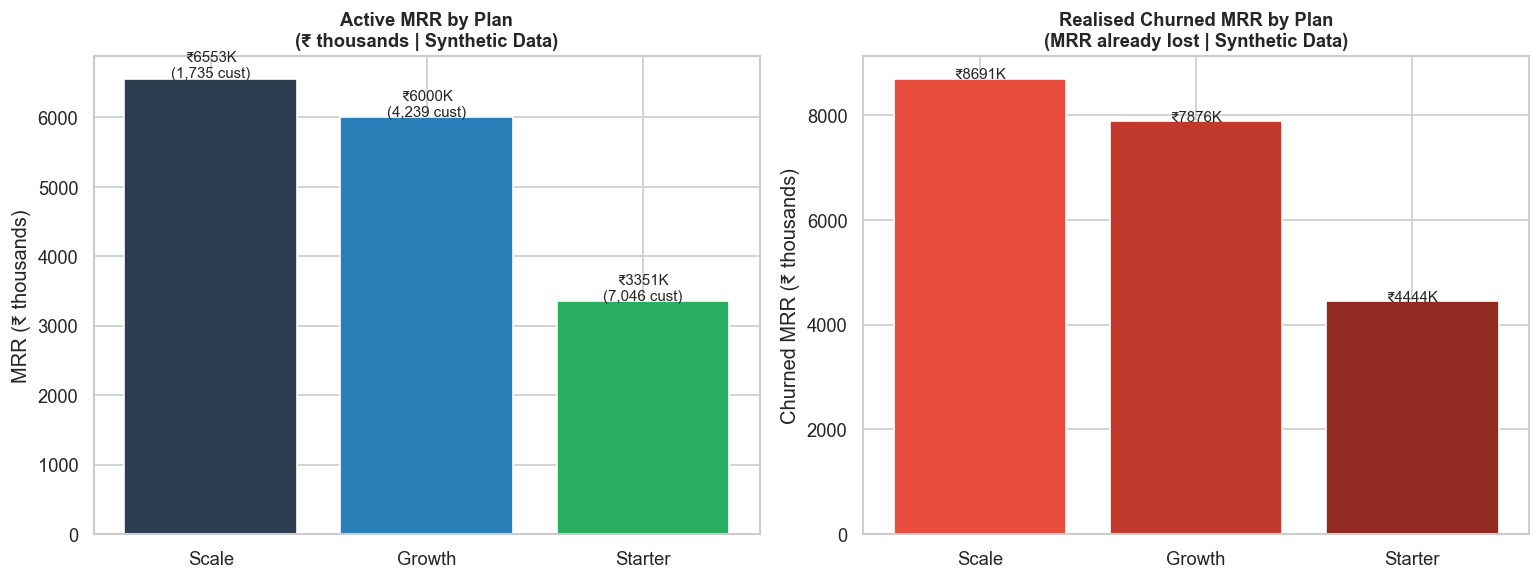

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plan_colors = ['#2c3e50', '#2980b9', '#27ae60']

# Left: Active MRR by plan
axes[0].bar(df_mrr['plan'], df_mrr['active_mrr'] / 1000, color=plan_colors, edgecolor='white')
axes[0].set_title('Active MRR by Plan\n(₹ thousands | Synthetic Data)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('MRR (₹ thousands)')
for i, (_, row) in enumerate(df_mrr.iterrows()):
    axes[0].text(i, row['active_mrr']/1000 + 20, f'₹{row["active_mrr"]/1000:.0f}K\n({row["active_customers"]:,} cust)', ha='center', fontsize=9)

# Right: Realised churned MRR (measure 1)
axes[1].bar(df_mrr['plan'], df_mrr['realised_churned_mrr'] / 1000, color=['#e74c3c', '#c0392b', '#922b21'], edgecolor='white')
axes[1].set_title('Realised Churned MRR by Plan\n(MRR already lost | Synthetic Data)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Churned MRR (₹ thousands)')
for i, (_, row) in enumerate(df_mrr.iterrows()):
    axes[1].text(i, row['realised_churned_mrr']/1000 + 10, f'₹{row["realised_churned_mrr"]/1000:.0f}K', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '08_mrr_by_plan.png', bbox_inches='tight')
plt.show()

## 2. Realised Churned Revenue Over Time (Q9 — Measure 1)

<cell>:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


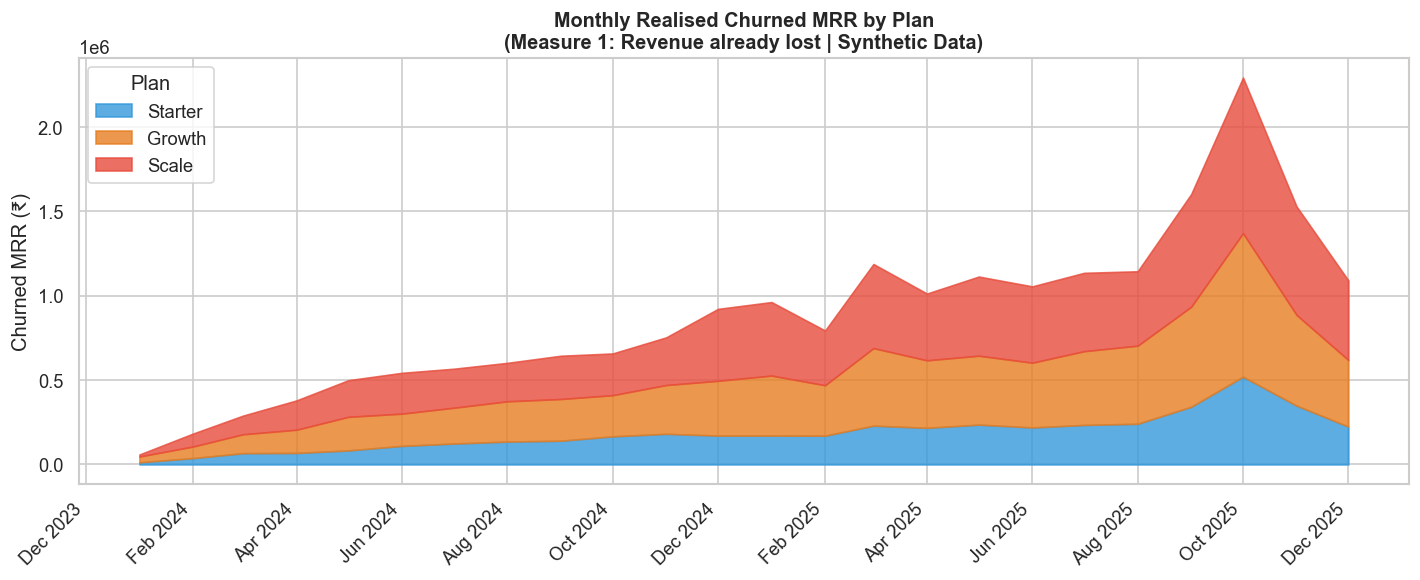

In [4]:
df_real = pd.read_sql('SELECT * FROM revenue_realised_churned WHERE churn_month IS NOT NULL ORDER BY churn_month', conn)
df_real['churn_month'] = pd.to_datetime(df_real['churn_month'])

# Pivot by plan for stacked area
pivot = df_real.pivot_table(index='churn_month', columns='plan', values='mrr_lost', fill_value=0)

fig, ax = plt.subplots(figsize=(12, 5))
plan_colors_stacked = {'Starter': '#3498db', 'Growth': '#e67e22', 'Scale': '#e74c3c'}

bottom = np.zeros(len(pivot))
for plan in ['Starter', 'Growth', 'Scale']:
    if plan in pivot.columns:
        ax.fill_between(pivot.index, bottom, bottom + pivot[plan].values,
                        label=plan, color=plan_colors_stacked[plan], alpha=0.8)
        bottom += pivot[plan].values

ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=45, ha='right')

ax.set_title('Monthly Realised Churned MRR by Plan\n(Measure 1: Revenue already lost | Synthetic Data)', fontsize=12, fontweight='bold')
ax.set_ylabel('Churned MRR (₹)')
ax.legend(title='Plan')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '08_realised_churned_mrr_over_time.png', bbox_inches='tight')
plt.show()

## 3. Exposed Revenue at Risk (Q9 — Measure 2)

In [5]:
df_exp = pd.read_sql('SELECT * FROM revenue_exposed_at_risk ORDER BY exposed_mrr DESC', conn)
print('Measure 2: MRR held by currently active but high-risk customers')
print(df_exp.to_string(index=False))
print(f"\nTotal exposed MRR: ₹{df_exp['exposed_mrr'].sum():,.0f}")
print(f"This represents {df_exp['exposed_mrr'].sum() / total_active_mrr * 100:.1f}% of total active MRR")

Measure 2: MRR held by currently active but high-risk customers
   plan billing_cycle  high_risk_customers  exposed_mrr  avg_mrr_at_risk
  Scale       Monthly                    5     19995.00          3999.00
 Growth        Annual                    6      7465.02          1244.17
 Growth       Monthly                    4      5996.00          1499.00
Starter       Monthly                   11      5489.00           499.00
  Scale        Annual                    1      3319.17          3319.17
Starter        Annual                    2       828.34           414.17

Total exposed MRR: ₹43,093
This represents 0.3% of total active MRR


## 4. Projected Revenue at Risk (Q9 — Measure 3)

In [6]:
df_proj = pd.read_sql('SELECT * FROM revenue_projected_risk ORDER BY projected_mrr_at_risk_next_month DESC', conn)
print('Measure 3: Projected MRR at risk next month if current churn rate holds')
print(df_proj[['plan','active_customers','total_active_mrr','monthly_churn_rate_pct','projected_mrr_at_risk_next_month']].to_string(index=False))
print(f"\nTotal projected MRR at risk next month: ₹{df_proj['projected_mrr_at_risk_next_month'].sum():,.0f}")
print(f"Annualised: ₹{df_proj['projected_annual_mrr_at_risk'].sum():,.0f}")

Measure 3: Projected MRR at risk next month if current churn rate holds
   plan  active_customers  total_active_mrr  monthly_churn_rate_pct  projected_mrr_at_risk_next_month
  Scale              1735        6553481.22                   56.71                        3716479.20
 Growth              4239        5999537.64                   56.38                        3382539.32
Starter              7046        3350959.65                   56.70                        1899994.12

Total projected MRR at risk next month: ₹8,999,013
Annualised: ₹107,988,152


## 5. Revenue at Risk Summary Dashboard (3 Measures)

<cell>:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


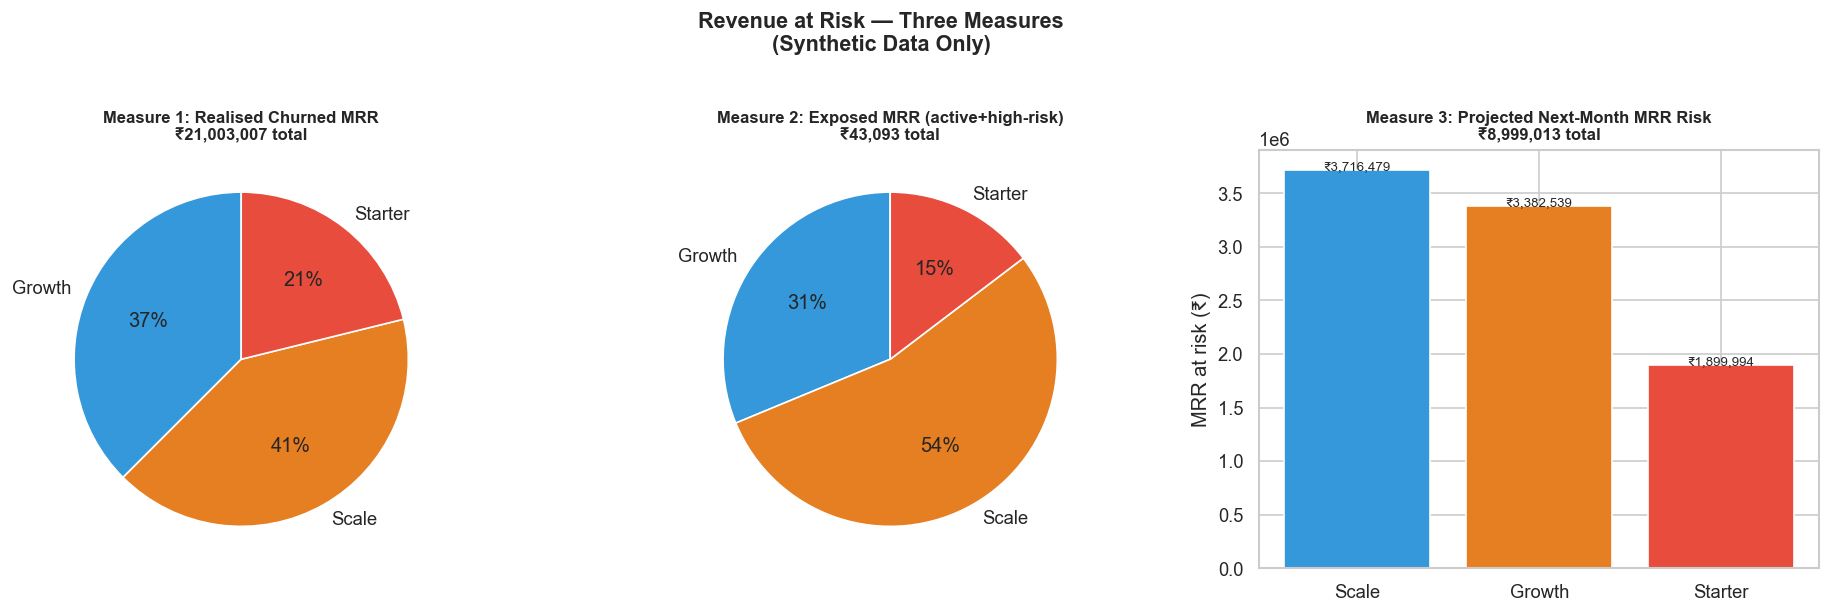

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Measure 1
ax = axes[0]
m1_total = df_real.groupby('plan')['mrr_lost'].sum().reset_index()
ax.pie(m1_total['mrr_lost'], labels=m1_total['plan'], autopct='%1.0f%%',
       colors=['#3498db','#e67e22','#e74c3c'], startangle=90)
ax.set_title(f'Measure 1: Realised Churned MRR\n₹{m1_total["mrr_lost"].sum():,.0f} total', fontsize=10, fontweight='bold')

# Measure 2
ax = axes[1]
m2_grp = df_exp.groupby('plan')['exposed_mrr'].sum().reset_index()
if len(m2_grp) > 0:
    ax.pie(m2_grp['exposed_mrr'], labels=m2_grp['plan'], autopct='%1.0f%%',
           colors=['#3498db','#e67e22','#e74c3c'][:len(m2_grp)], startangle=90)
    ax.set_title(f'Measure 2: Exposed MRR (active+high-risk)\n₹{m2_grp["exposed_mrr"].sum():,.0f} total', fontsize=10, fontweight='bold')
else:
    ax.text(0.5, 0.5, 'No high-risk\nactive customers\nwith usage data', ha='center', va='center', fontsize=12)
    ax.set_title('Measure 2: Exposed MRR', fontsize=10, fontweight='bold')

# Measure 3
ax = axes[2]
ax.bar(df_proj['plan'], df_proj['projected_mrr_at_risk_next_month'], color=['#3498db','#e67e22','#e74c3c'][:len(df_proj)], edgecolor='white')
ax.set_title(f'Measure 3: Projected Next-Month MRR Risk\n₹{df_proj["projected_mrr_at_risk_next_month"].sum():,.0f} total', fontsize=10, fontweight='bold')
ax.set_ylabel('MRR at risk (₹)')
for i, (_, row) in enumerate(df_proj.iterrows()):
    ax.text(i, row['projected_mrr_at_risk_next_month'] + 500, f'₹{row["projected_mrr_at_risk_next_month"]:,.0f}', ha='center', fontsize=8)

plt.suptitle('Revenue at Risk — Three Measures\n(Synthetic Data Only)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '08_revenue_at_risk_three_measures.png', bbox_inches='tight')
plt.show()

## 6. Cross-Finding Synthesis (Q12 — What should the business do?)

This cell summarises all findings into business-facing recommendations. Full playbook is in `playbook/churn_playbook.md`.

In [8]:
print("="*70)
print("ZORVIO CHURN INTELLIGENCE — SYNTHESIS SUMMARY")
print("(All from synthetic data — not real business findings)")
print("="*70)

print("""
Q1/Q2 — TREND:
  • Baseline monthly total churn: ~6%. Voluntary churn: ~5%.
  • Outage event (Sep/Oct 2025) was ASSOCIATED with a voluntary churn spike (~10.8%).
  • Churn returned to baseline post-event. (F001)

Q3 — SEGMENTS:
  • Starter plan and Monthly billing customers churn at significantly higher rates.
  • Examine plan × billing cross-tab for confounding.

Q4 — COHORTS:
  • Average M6 retention: ~69%. No strong seasonal cohort variation.
  • Churned customers average ~6 months tenure — early-period exits are common. (F003, F004)

Q5/Q6 — USAGE:
  • Inactive customers (0 sessions in 30d) churn at substantially higher rates.
  • Collaboration feature use is associated with lower churn (stickiness signal).

Q7 — CHANNELS:
  • App Store channel shows highest churn — confounded by Starter plan skew.
  • Referral channel shows lowest churn. Check CAC-adjusted ROI before action.

Q8/Q9 — REVENUE:
  • Scale plan holds highest ARPU but smallest customer base.
  • Starter plan drives highest absolute churned MRR volume.
  • Three revenue-at-risk measures computed (realised, exposed, projected).

Q10 — LEADING INDICATORS:
  • 30-day inactivity > open support ticket > low collaboration use (relative risk order).
  • Composite risk score shows monotone churn increase: Low < Medium < High < Critical.

Q11 — HIGH-RISK GROUPS:
  • Critical/High risk active customers identified with composite MRR exposure.
  • Recommended action: CS outreach prioritised by MRR × risk_score.

Q12 — RECOMMENDATIONS: See playbook/churn_playbook.md
""")

ZORVIO CHURN INTELLIGENCE — SYNTHESIS SUMMARY
(All from synthetic data — not real business findings)

Q1/Q2 — TREND:
  • Baseline monthly total churn: ~6%. Voluntary churn: ~5%.
  • Outage event (Sep/Oct 2025) was ASSOCIATED with a voluntary churn spike (~10.8%).
  • Churn returned to baseline post-event. (F001)

Q3 — SEGMENTS:
  • Starter plan and Monthly billing customers churn at significantly higher rates.
  • Examine plan × billing cross-tab for confounding.

Q4 — COHORTS:
  • Average M6 retention: ~69%. No strong seasonal cohort variation.
  • Churned customers average ~6 months tenure — early-period exits are common. (F003, F004)

Q5/Q6 — USAGE:
  • Inactive customers (0 sessions in 30d) churn at substantially higher rates.
  • Collaboration feature use is associated with lower churn (stickiness signal).

Q7 — CHANNELS:
  • App Store channel shows highest churn — confounded by Starter plan skew.
  • Referral channel shows lowest churn. Check CAC-adjusted ROI before action.

Q8/Q

In [9]:
# Export findings register summary
df_findings = pd.read_csv('../outputs/findings_register.csv')
print(f'Findings register: {len(df_findings)} entries')
print(df_findings[['finding_id','question_id','finding','confidence']].to_string(index=False))

Findings register: 12 entries
finding_id question_id                                                                                                            finding confidence
      F001          Q1        Current monthly churn is steady at ~6.3% under normal operations; cumulative lifetime churn share is 56.6%.       High
      F002          Q2 Churn is event-driven and sensitive to infrastructure reliability rather than undergoing secular structural decay.       High
      F003       Q3/Q4 Product suffers from steep early mortality cliff in first 90 days; hazard rate drops over 20x for mature accounts.       High
      F004          Q4                                                               Churned customers leave early in customer lifecycle.       High
      F005          Q3                                  Plan tier alone does not determine churn hazard when accounting for time at risk.       High
      F006          Q3                                         Annual billin

In [10]:
conn.close()